In [1]:
from scipy.spatial.transform import Rotation
import matplotlib.pyplot as plt
import pandas as pd
import numpy  as np
import json, os, datetime
pd.set_option('display.max_columns', None)

In [2]:
OPTIONS = json.loads(open('../info.json', 'r').read())
TEST    = OPTIONS.get('test', 1)
GRAVITY = OPTIONS['gravity']
RESULTS = f'../Dataset/test{TEST}/results'
COLUMNS = ['time', 'static', 'ax', 'ay', 'az', 'ref_roll', 'ref_pitch', 'ref_yaw', 'ref_wx', 'ref_wy', 'ref_wz']

strategy = json.loads(open(f'{RESULTS}/attitude.json', 'r').read())
print('SOURCE:', f'{RESULTS}/corrected.csv', '+', f'{RESULTS}/attitude.csv', f'({strategy["strategy"]})')

SOURCE: ../Dataset/test1/results/corrected.csv + ../Dataset/test1/results/attitude.csv (kalman_fusion)


# IMPORTANDO DADOS
- O acelerômetro filtrado e corrigido do `2 - Correction` e a atitude da estratégia que rodou por último no `3 - Attitude`, casados por `time`

In [3]:
attitude = pd.read_csv(f'{RESULTS}/attitude.csv').drop(columns='static', errors='ignore')
df       = pd.read_csv(f'{RESULTS}/corrected.csv', usecols=COLUMNS).merge(attitude, on='time')
moving   = ~df.static.to_numpy()
time     = df.time.to_numpy()

print(len(df), 'amostras |', moving.sum(), 'em movimento')
df.head()

1800 amostras | 800 em movimento


,time,static,ref_pitch,ref_roll,ref_yaw,ref_wx,ref_wy,ref_wz,ax,ay,az,pitch,pitch_ref,roll,roll_ref,yaw,yaw_ref
0,0.0,False,0.304871,-71.390541,2.771970,-48.363254,-0.461426,0.424375,0.212621,10.733956,0.541538,1.599845,0.304871,-71.897500,-71.390541,2.771970,2.771970
1,0.1,False,0.337243,-76.661753,2.723841,-56.744132,1.081554,0.104249,0.236557,11.498772,0.493097,1.684539,0.337243,-75.608591,-76.661753,2.768606,2.723841
2,0.2,False,0.366750,-82.677810,2.667691,-63.259749,-0.383746,0.248578,0.121950,12.716274,1.420537,1.795699,0.366750,-81.710402,-82.677810,2.698839,2.667691
3,0.3,False,0.387721,-89.209529,2.743322,-66.654402,0.041597,0.372268,0.233087,12.446751,0.857032,1.143599,0.387721,-89.879315,-89.209529,2.611133,2.743322
4,0.4,False,0.442381,-95.913135,2.624720,-67.172037,1.487548,0.737216,0.287146,12.369719,0.464970,1.321783,0.442381,-96.584411,-95.913135,2.525740,2.624720


# ACELERAÇÃO VERTICAL
- A atitude leva a força específica do corpo para a navegação ($z$ para baixo), e somando $g$ sobra a aceleração vertical do sensor
- O heave sai fora do filtro de Kalman: ele só usa o pitch e o roll que a etapa 3 entregou, e a terceira linha de $R = R_z R_y R_x$ nem depende da proa:

$$a_z = -\sin\theta\, f_x + \sin\phi\cos\theta\, f_y + \cos\phi\cos\theta\, f_z + g$$

In [4]:
# (R v)_z: A TERCEIRA LINHA DE R = Rz Ry Rx, QUE NÃO DEPENDE DA PROA
def vertical(v, pitch, roll):
    p, r = np.radians(pitch), np.radians(roll)
    return -np.sin(p)*v[..., 0] + np.sin(r)*np.cos(p)*v[..., 1] + np.cos(r)*np.cos(p)*v[..., 2]


df['accel'] = vertical(df[['ax', 'ay', 'az']].to_numpy(), df.pitch, df.roll) + GRAVITY
df.groupby('static').accel.describe()

,count,mean,std,min,25%,50%,75%,max
static,,,,,,,,
False,800.0,-0.020810,0.794017,-4.114485,-0.347047,-0.012805,0.352234,2.762986
True,1000.0,0.000043,0.020922,-0.059992,-0.013852,-0.000472,0.014022,0.103785


# INTEGRAÇÃO DUPLA COM PASSA-ALTA
- Aceleração vira posição por duas integrações, e um viés qualquer cresceria em $t^2$. Cada integração é uma seção de segunda ordem que integra acima de $\omega_c$ e zera o DC:

$$\frac{s}{s^2 + 2\zeta\omega_c s + \omega_c^2} \quad\Rightarrow\quad H(s) = \frac{s^2}{(s^2 + 2\zeta\omega_c s + \omega_c^2)^2}$$

- $H(0) = 0$: o mar tem média zero, e o que é lento (deriva, viés, erro de $g$) não vira heave. $\omega_c = 2\pi/(10\,T_h)$ como na EP 2 092 402, que passa períodos até $10\,T_h$
- A seção integra $z'' = u - 2\zeta\omega_c z' - \omega_c^2 z$ com a entrada linear dentro do passo e parte em regime, $z = u/\omega_c^2$, sem o degrau do primeiro instante. $z'$ é o integrador limitado, $z''$ o passa-alta

In [5]:
# SEÇÃO z'' = u - 2ζω z' - ω² z COM A ENTRADA LINEAR NO PASSO, ESPELHO DO Section DO firmware
class Section:
    GAP = 0.5    # s SEM AMOSTRA: A INTEGRAÇÃO NÃO ATRAVESSA O BURACO, RECOMEÇA EM REGIME

    def __init__(self, period, damping):
        self.w      = 2*np.pi/(10*period)
        self.zeta   = damping
        self.primed = False

    def update(self, u, dt):
        if not self.primed or dt > self.GAP:
            self.z0, self.z1, self.z2, self.u, self.primed = u/self.w**2, 0.0, 0.0, u, True
            return self

        e, w = self.zeta, self.w
        w0   = self.u - 2*e*w*self.z1 - w*w*self.z0
        w1   = u - 2*e*w*self.z1 - w*w*self.z0
        self.z0 += self.z1*dt + dt*dt*(2*w0 + w1)/6
        self.z1 += dt*(w0 + w1)/2
        self.z2  = u - 2*e*w*self.z1 - w*w*self.z0
        self.u   = u
        return self


# HEAVE: DUAS SEÇÕES EM CASCATA NA ACELERAÇÃO VERTICAL, SAÍDA z' DE CADA UMA
def getHeave(accel, time, period, damping):
    velocity, position = Section(period, damping), Section(period, damping)
    return np.array([position.update(velocity.update(a, dt).z1, dt).z1 for a, dt in zip(accel, np.diff(time, prepend=time[0]))])


# O MESMO FILTRO SOBRE UM DESLOCAMENTO: H(s)s² SÃO DUAS SEÇÕES PASSA-ALTA
def getBand(values, time, period, damping):
    first, second = Section(period, damping), Section(period, damping)
    return np.array([second.update(first.update(x, dt).z2, dt).z2 for x, dt in zip(values, np.diff(time, prepend=time[0]))])

# REFERÊNCIA DE HEAVE
- O ensaio gira em torno de um pivô fixo: o sensor a $r$ do pivô desce $z = (R\,r)_z$, sem integração nenhuma
- O heave verdadeiro é a oscilação de $z$ em torno da média móvel centrada de `TREND` s: a altura média do pêndulo sobe enquanto o balanço decai, e essa tendência lenta é justamente o que o passa-alta tira
- $r$ sai do acelerômetro em movimento por mínimos quadrados: o que sobra da gravidade é o braço de alavanca, linear em $r$:

$$f - R^\top g = \left([\dot\omega\times] + [\omega\times]^2\right) r$$

In [6]:
R       = Rotation.from_euler('xyz', df[['ref_roll', 'ref_pitch', 'ref_yaw']].to_numpy(), degrees=True).as_matrix()
w       = np.radians(df[['ref_wx', 'ref_wy', 'ref_wz']].to_numpy())
segment = np.cumsum(np.r_[0, np.diff(time) > Section.GAP])
dw      = np.vstack([np.gradient(w[segment == k], time[segment == k], axis=0) for k in np.unique(segment)])
skew    = lambda v: np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])
K       = np.array([skew(a) + skew(o) @ skew(o) for a, o in zip(dw, w)])
rest    = df[['ax', 'ay', 'az']].to_numpy() - np.einsum('nji,j->ni', R, [0, 0, -GRAVITY])

TREND   = 10.0    # s DA MÉDIA MÓVEL QUE SEPARA A OSCILAÇÃO DA TENDÊNCIA: VÁRIOS PERÍODOS DO HEAVE DO PÊNDULO
PIVOT   = np.linalg.lstsq(K[moving].reshape(-1, 3), rest[moving].reshape(-1), rcond=None)[0]
geo     = R[:, 2, :] @ PIVOT
window  = int(round(TREND / np.median(np.diff(time))))
truth   = geo - pd.Series(geo).groupby(segment).transform(lambda part: part.rolling(window, center=True, min_periods=1).mean()).to_numpy()

print('r =', PIVOT.round(3), 'm | resíduo', np.sqrt(np.mean((rest - np.einsum('nij,j->ni', K, PIVOT))[moving]**2)).round(4), 'm/s²')

r = [-0.195 -1.939  0.057] m | resíduo 0.1347 m/s²


# PERÍODO E AMORTECIMENTO
- $T_h$ e $\zeta$ na grade, pelo menor erro RMS contra o heave verdadeiro depois de `SETTLE` s de assentamento: o erro inclui a forma da banda, que é o que o MRU entrega
- O pêndulo desce duas vezes por balanço e o $T_h$ que sai daqui é o dele; num navio $T_h$ é o período das ondas, de 5 a 20 s

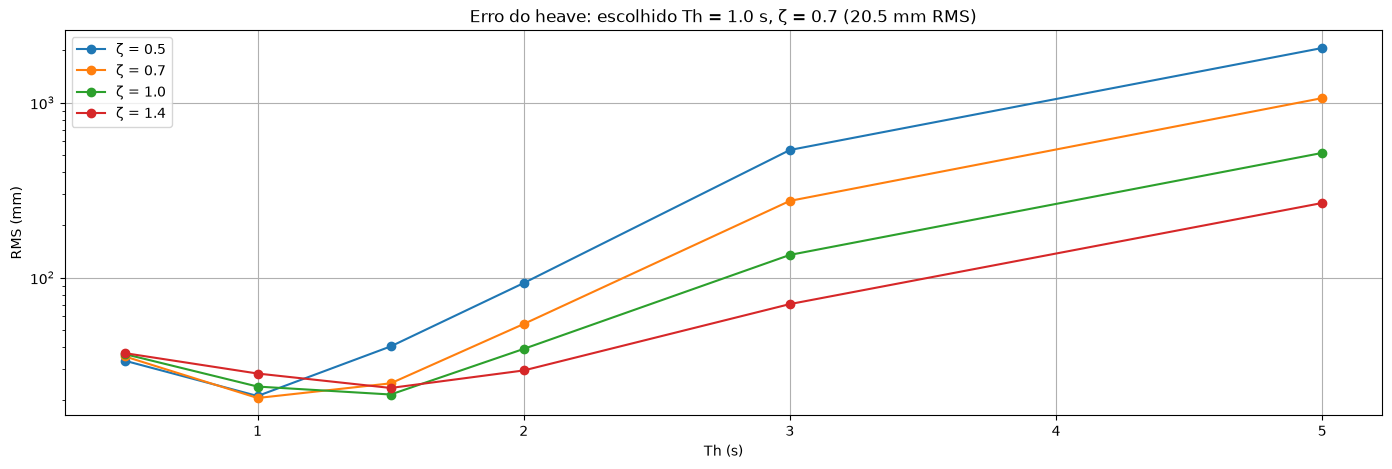

,0.5,0.7,1.0,1.4
0.5,33.5,35.5,36.6,37.0
1.0,21.1,20.5,23.8,28.3
1.5,40.4,24.9,21.5,23.4
2.0,93.1,54.3,39.1,29.5
3.0,536.5,274.6,134.9,70.6
5.0,2053.2,1061.6,516.2,267.1


In [7]:
PERIODS  = [0.5, 1.0, 1.5, 2.0, 3.0, 5.0]    # s
DAMPINGS = [0.5, 0.7, 1.0, 1.4]
SETTLE   = 20.0                              # s DO TRANSITÓRIO DE PARTIDA FORA DA MÉTRICA
settled  = moving & (time > time[moving][0] + SETTLE)


def getError(period, damping):
    error = getHeave(df.accel.to_numpy(), time, period, damping) - truth
    return float(np.sqrt(np.mean(error[settled]**2)))


grid             = pd.DataFrame([[getError(period, damping) for damping in DAMPINGS] for period in PERIODS], index=PERIODS, columns=DAMPINGS)
PERIOD, DAMPING  = grid.stack().idxmin()

plt.figure(figsize=(17, 5))
for damping in DAMPINGS:
    plt.plot(PERIODS, 1000*grid[damping], marker='o', label=f'ζ = {damping}')

plt.title(f'Erro do heave: escolhido Th = {PERIOD} s, ζ = {DAMPING} ({1000*grid.loc[PERIOD, DAMPING]:.1f} mm RMS)'); plt.xlabel('Th (s)'); plt.ylabel('RMS (mm)'); plt.yscale('log'); plt.grid(); plt.legend()
plt.show()
(1000*grid).round(1)

# VISUALIZAÇÃO FINAL

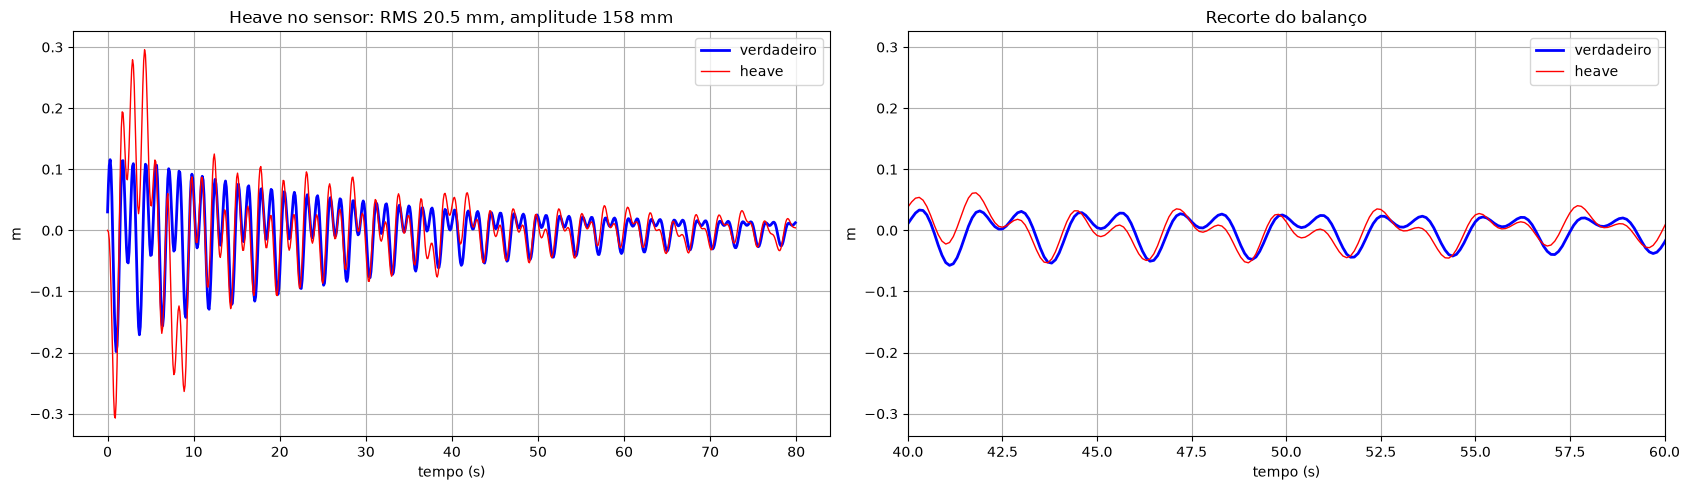

In [8]:
heave = getHeave(df.accel.to_numpy(), time, PERIOD, DAMPING)
error = (heave - truth)[settled]
plot  = np.where(moving, time, np.nan)

plt.figure(figsize=(17, 5))
plt.subplot(1, 2, 1)
plt.plot(plot, truth, label='verdadeiro', color='blue', linewidth=2)
plt.plot(plot, heave, label='heave', color='red', linewidth=1)
plt.title(f'Heave no sensor: RMS {1000*np.sqrt(np.mean(error**2)):.1f} mm, amplitude {1000*np.ptp(truth[settled]):.0f} mm'); plt.xlabel('tempo (s)'); plt.ylabel('m'); plt.grid(); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(plot, truth, label='verdadeiro', color='blue', linewidth=2)
plt.plot(plot, heave, label='heave', color='red', linewidth=1)
plt.xlim(40, 60)
plt.title('Recorte do balanço'); plt.xlabel('tempo (s)'); plt.ylabel('m'); plt.grid(); plt.legend()

plt.tight_layout()
plt.show()

# SALVANDO O HEAVE
- `band_x/y/z` é $H(s)s^2$ aplicado a cada coluna da terceira linha de $R$ estimada: o `5 - Lever` translada o heave com elas, sem refazer o filtro

In [9]:
rows   = vertical(np.eye(3)[:, None, :], df.pitch.to_numpy(), df.roll.to_numpy())
output = df[['time', 'static']].assign(heave=heave, heave_ref=truth, **{f'band_{axis}': getBand(rows[j], time, PERIOD, DAMPING) for j, axis in enumerate('xyz')})

output.to_csv(f'{RESULTS}/heave.csv', index=None)
output

,time,static,heave,heave_ref,band_x,band_y,band_z
0,0.0,False,0.000000,0.030163,0.000000,0.000000e+00,0.000000
1,0.1,False,-0.002453,0.074951,-0.001349,-1.649286e-02,-0.056734
2,0.2,False,-0.015224,0.106253,-0.002870,-3.250103e-02,-0.141519
3,0.3,False,-0.045848,0.115703,0.008065,-3.604018e-02,-0.244133
4,0.4,False,-0.094409,0.098720,0.003815,-2.249773e-02,-0.302400
...,...,...,...,...,...,...,...
1795,279.4,True,-0.000940,0.000055,-0.000526,5.187891e-06,0.000211
1796,279.5,True,-0.000402,0.000055,-0.000574,8.627985e-06,0.000149
1797,279.6,True,0.000367,0.000052,-0.000132,5.120894e-07,0.000062
1798,279.7,True,0.001121,0.000052,0.000354,-1.030976e-05,0.000026


In [10]:
os.makedirs('Backup', exist_ok=True)
saved  = [name for name in os.listdir('Backup') if name.startswith('heave_')]
index  = len(saved) + 1

output = f'Backup/heave_{index}'
os.makedirs(output, exist_ok=True)

metrics = {'rms': float(np.sqrt(np.mean(error**2))), 'amplitude': float(np.ptp(truth[settled])), 'corr': float(np.corrcoef(heave[settled], truth[settled])[0, 1])}

results = {
    'period':   PERIOD,
    'damping':  DAMPING,
    'gravity':  GRAVITY,
    'pivot':    PIVOT.tolist(),
    'grid':     grid.rename(index=str, columns=str).to_dict('index'),    # RMS EM m, Th NA LINHA E zeta NA COLUNA
    'metrics':  metrics,
    'attitude': strategy['strategy'],
    'dataset':  {'path': f'{RESULTS}/corrected.csv', 'samples': len(df), 'settle': SETTLE, 'trend': TREND}
}

record = {
    'strategy': 'heave',
    'backup':   f'4 - Heave/{output}',
    'attitude': strategy['strategy'],
    'pivot':    PIVOT.tolist(),
    'trend':    TREND,
    'metrics':  metrics
}

pd.Series(results).to_json(f'{output}/info.json', indent=4)
pd.Series(record).to_json(f'{RESULTS}/heave.json', indent=4)
print(output, '->', f'{RESULTS}/heave.json')
record

Backup/heave_2 -> ../Dataset/test1/results/heave.json


{'strategy': 'heave',
 'backup': '4 - Heave/Backup/heave_2',
 'attitude': 'kalman_fusion',
 'pivot': [-0.195177911909646, -1.9386759643305596, 0.056803804589038],
 'trend': 10.0,
 'metrics': {'rms': 0.020513170173100247,
  'amplitude': 0.1582121066254778,
  'corr': 0.7678511708602929}}

# EXPORTANDO PARA O FIRMWARE
- O firmware integra o heave depois da atitude, com as mesmas duas seções; `HEAVE_GRAVITY` é o mesmo $g$ da correção
- `HEAVE_PERIOD` é o knob de bordo: num navio ele vai para o período das ondas

In [11]:
FIRMWARE = '../../Hardware/Embedded/Main/objects/processing/heave'

header = f'''#ifndef HEAVE_CONFIG_H
#define HEAVE_CONFIG_H

// GERADO POR Calibration/4 - Heave/1 - Model.ipynb EM {datetime.date.today():%d/%m/%Y}
#define HEAVE_PERIOD  {PERIOD:.6f}f    // s, Th: o filtro passa periodos ate 10 Th
#define HEAVE_DAMPING {DAMPING:.6f}f    // zeta das secoes
#define HEAVE_GRAVITY {GRAVITY:.6f}f    // m/s^2 local, a mesma da correcao

#endif
'''

open(f'{FIRMWARE}/config.h', 'w').write(header)
print(header)

#ifndef HEAVE_CONFIG_H
#define HEAVE_CONFIG_H

// GERADO POR Calibration/4 - Heave/1 - Model.ipynb EM 15/10/2026
#define HEAVE_PERIOD  1.000000f    // s, Th: o filtro passa periodos ate 10 Th
#define HEAVE_DAMPING 0.700000f    // zeta das secoes
#define HEAVE_GRAVITY 9.785000f    // m/s^2 local, a mesma da correcao

#endif

